# Churn EDA: Stage 0 first-pass notebook (DRAFT, not verified)

> **Status: this is a best-effort first pass.** Claude generated it with the `churn-eda-profiling` skill (Stage 0), working directly from the raw files in `data/`. **Nobody has reviewed it.** It exists so the review step (`eda_review.md`) has something concrete to check and correct. It is not the verified analysis. The build-stage notebook is `notebooks/eda_churn.ipynb`, and this notebook does not touch it or the `eda/` modules.

**Confidence tags used throughout**

| Tag | Meaning |
|---|---|
| **[computed]** | The number comes straight from code in this notebook. The *interpretation* next to it can still be wrong. |
| **[eyeballed]** | Read off a chart or a descriptive split. No statistical test was run. |
| **[assumption]** | Something the data does not state, which I had to assume. |

**Scope (skill Stage 0, step 2):** schema and dtypes per source, missingness, the zero-activity customers, distribution shape and outliers, category/channel/region breakdowns, churn rate overall and by candidate categorical drivers, and the monthly volume trend. Two quick extras came up while loading, so I ran them too: a check of the parquet extract against the row-level table, and a few sanity checks.

**The sources are opened read-only.** SQLite is opened with `mode=ro`, and the SHA-256 of every data file is compared at the start and at the end.

The written-up drafts are `EDA_FINDINGS_DRAFT.md`, `MODEL_RECOMMENDATION_DRAFT.md` and `DATA_ISSUES_DRAFT.md`, at the repo root.

In [1]:
import hashlib
import sqlite3
from contextlib import closing
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy import stats

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_rows", 60)

# Works whether the notebook is run from the repo root or from notebooks/.
ROOT = Path.cwd() if (Path.cwd() / "data").is_dir() else Path.cwd().parent
DATA = ROOT / "data"
CUSTOMERS_CSV = DATA / "customers.csv"
TRANSACTIONS_DB = DATA / "transactions.db"
MONTHLY_PARQUET = DATA / "transactions_monthly_agg.parquet"
SOURCES = [CUSTOMERS_CSV, TRANSACTIONS_DB, MONTHLY_PARQUET]


def sha256(path: Path) -> str:
    return hashlib.sha256(path.read_bytes()).hexdigest()


HASHES_AT_START = {p.name: sha256(p) for p in SOURCES}

# Chart styling: light chart surface, solid hairline grid, recessive axes.
# Colour roles are fixed for the whole notebook:
#   BLUE   - single-series default; "retained" (churned = 0); row-level transactions.db
#   ORANGE - "churned" (churned = 1) only
#   AQUA   - the parquet extract only (always direct-labelled; it is below 3:1 contrast)
SURFACE, INK, INK_2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 10, "axes.titlelocation": "left", "axes.grid": True, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False,
    "grid.color": GRID, "grid.linewidth": 0.6, "grid.linestyle": "-",
    "xtick.color": AXIS, "ytick.color": AXIS, "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2,
    "lines.linewidth": 1.5, "lines.solid_capstyle": "round", "lines.solid_joinstyle": "round",
    "font.size": 9, "figure.dpi": 100,
})
for p in SOURCES:
    print(f"{p.relative_to(ROOT).as_posix():<40} {p.stat().st_size:>9,} bytes")

data/customers.csv                          48,041 bytes
data/transactions.db                       884,736 bytes
data/transactions_monthly_agg.parquet       68,940 bytes


## 1. Load all three sources (read-only)

In [2]:
customers_raw = pd.read_csv(CUSTOMERS_CSV)

# mode=ro: the database is opened read-only, so nothing in this notebook can write to it.
with closing(sqlite3.connect(TRANSACTIONS_DB.resolve().as_uri() + "?mode=ro", uri=True)) as con:
    sqlite_objects = pd.read_sql("SELECT type, name, tbl_name FROM sqlite_master ORDER BY type, name", con)
    sqlite_declared = pd.read_sql(
        "SELECT name AS column_name, type AS declared_sqlite_type FROM pragma_table_info('transactions')", con
    )
    transactions_raw = pd.read_sql("SELECT * FROM transactions", con)

monthly_raw = pd.read_parquet(MONTHLY_PARQUET)

print(sqlite_objects.to_string(index=False), "\n")
for name, df in [("customers.csv", customers_raw),
                 ("transactions.db :: transactions", transactions_raw),
                 ("transactions_monthly_agg.parquet", monthly_raw)]:
    print(f"{name:<34} rows = {len(df):>6,}   columns = {df.shape[1]}")

 type                         name     tbl_name
index idx_transactions_customer_id transactions
table                 transactions transactions 

customers.csv                      rows =  1,500   columns = 5
transactions.db :: transactions    rows = 11,742   columns = 6
transactions_monthly_agg.parquet   rows =  8,086   columns = 5


## 2. Schema and dtypes per source

Only light parsing is applied. `signup_date` becomes a date and `txn_timestamp` (stored as TEXT in SQLite) becomes a datetime. `txn_date` and `txn_month` are derived from the timestamp. Everything else is left exactly as loaded.

In [3]:
customers = customers_raw.assign(signup_date=pd.to_datetime(customers_raw["signup_date"], format="%Y-%m-%d"))

transactions = transactions_raw.assign(
    txn_timestamp=pd.to_datetime(transactions_raw["txn_timestamp"], format="ISO8601")
)
transactions["txn_date"] = transactions["txn_timestamp"].dt.normalize()
transactions["txn_month"] = transactions["txn_timestamp"].dt.to_period("M").dt.to_timestamp()

monthly = monthly_raw.copy()  # parquet already carries types (txn_month is a timestamp)

assert customers["signup_date"].notna().all() and transactions["txn_timestamp"].notna().all()


def schema_table(raw: pd.DataFrame, parsed: pd.DataFrame) -> pd.DataFrame:
    return pd.DataFrame({
        "raw_dtype": raw.dtypes.astype(str),
        "parsed_dtype": parsed[raw.columns].dtypes.astype(str),
        "n_unique": raw.nunique(),
        "example": raw.iloc[0].astype(str),
    })


print("customers.csv")
display(schema_table(customers_raw, customers))
print("transactions.db :: transactions")
display(schema_table(transactions_raw, transactions))
display(sqlite_declared)
print("transactions_monthly_agg.parquet")
display(schema_table(monthly_raw, monthly))

customers.csv


,raw_dtype,parsed_dtype,n_unique,example
customer_id,int64,int64,1500,1
signup_date,str,datetime64[us],713,2026-04-16
acquisition_channel,str,str,4,organic
region,str,str,4,east
churned,int64,int64,2,1


transactions.db :: transactions


,raw_dtype,parsed_dtype,n_unique,example
customer_id,int64,int64,1419,2
txn_timestamp,str,datetime64[ns],11742,2024-09-04 21:56:57.516326572
category,str,str,6,sports
channel,str,str,3,web
amount,float64,float64,6860,80.12
is_returned,int64,int64,2,0


,column_name,declared_sqlite_type
0,customer_id,INTEGER
1,txn_timestamp,TEXT
2,category,TEXT
3,channel,TEXT
4,amount,REAL
5,is_returned,INTEGER


transactions_monthly_agg.parquet


,raw_dtype,parsed_dtype,n_unique,example
customer_id,int64,int64,1409,2
txn_month,datetime64[us],datetime64[us],30,2024-09-01 00:00:00
txn_count,int64,int64,6,1
total_amount,float64,float64,6218,80.12
return_count,int64,int64,4,0


In [4]:
print("signup_date range   :", customers["signup_date"].min().date(), "->", customers["signup_date"].max().date())
print("txn_timestamp range :", transactions["txn_timestamp"].min(), "->", transactions["txn_timestamp"].max())
print("parquet txn_month   :", monthly["txn_month"].min().date(), "->", monthly["txn_month"].max().date(),
      f"({monthly['txn_month'].nunique()} months)")
print("customer_id unique in customers.csv           :", customers["customer_id"].is_unique)
print("(customer_id, txn_month) unique in the parquet:", not monthly.duplicated(["customer_id", "txn_month"]).any())
print("parquet txn_month always first-of-month       :", bool((monthly["txn_month"].dt.day == 1).all()))
for col in ["acquisition_channel", "region", "churned"]:
    print(f"customers.{col}: {customers[col].value_counts().to_dict()}")
for col in ["category", "channel", "is_returned"]:
    print(f"transactions.{col}: {transactions[col].value_counts().to_dict()}")

signup_date range   : 2024-02-14 -> 2026-07-01
txn_timestamp range : 2024-02-29 18:44:13.034581037 -> 2026-07-31 23:50:29.001075447
parquet txn_month   : 2024-02-01 -> 2026-07-01 (30 months)
customer_id unique in customers.csv           : True
(customer_id, txn_month) unique in the parquet: True
parquet txn_month always first-of-month       : True
customers.acquisition_channel: {'organic': 609, 'paid_search': 431, 'referral': 295, 'social': 165}
customers.region: {'east': 385, 'north': 381, 'west': 380, 'south': 354}
customers.churned: {0: 1298, 1: 202}
transactions.category: {'home': 2008, 'grocery': 1979, 'sports': 1969, 'beauty': 1958, 'apparel': 1917, 'electronics': 1911}
transactions.channel: {'web': 5278, 'mobile_app': 4146, 'store': 2318}
transactions.is_returned: {0: 11151, 1: 591}


**Read [computed].** `customers.csv` has 1,500 rows, one per `customer_id` (unique), with columns `signup_date`, `acquisition_channel` (4 levels), `region` (4 levels) and a binary `churned` label. `transactions` has 11,742 rows. `txn_timestamp` is stored as **TEXT** (ISO-8601, nanosecond precision) and parses cleanly. The parquet extract has 8,086 rows at customer × month grain: `(customer_id, txn_month)` is unique and `txn_month` is always the first of the month. Date ranges: signups run 2024-02-14 → 2026-07-01, transactions 2024-02-29 → 2026-07-31, and parquet months 2024-02 → 2026-07 (30 months).

## 3. Missingness

There are two different kinds of "missing" here, and they need to be kept apart:
1. **Null values** in a column that exists (checked below).
2. **Rows that do not exist**: customers with no transactions at all. That is a population, not a data-quality gap (section 4).

In [5]:
null_counts = pd.concat(
    {name: df.isna().sum() for name, df in [("customers.csv", customers_raw),
                                             ("transactions.db", transactions_raw),
                                             ("parquet", monthly_raw)]},
    names=["source", "column"],
).rename("n_null")
display(null_counts.to_frame().T)

text_columns = {"customers.csv": (customers_raw, ["signup_date", "acquisition_channel", "region"]),
                "transactions.db": (transactions_raw, ["txn_timestamp", "category", "channel"])}
blank_strings = {f"{src}.{col}": int(df[col].astype(str).str.strip().eq("").sum())
                 for src, (df, cols) in text_columns.items() for col in cols}
print("total nulls across all three sources:", int(null_counts.sum()))
print("blank / whitespace-only strings in text columns:", sum(blank_strings.values()), blank_strings)

source customers.csv                                                transactions.db                                                       parquet            \
column   customer_id signup_date acquisition_channel region churned     customer_id txn_timestamp category channel amount is_returned customer_id txn_month   
n_null             0           0                   0      0       0               0             0        0       0      0           0           0         0   

source                                      
column txn_count total_amount return_count  
n_null         0            0            0

total nulls across all three sources: 0
blank / whitespace-only strings in text columns: 0 {'customers.csv.signup_date': 0, 'customers.csv.acquisition_channel': 0, 'customers.csv.region': 0, 'transactions.db.txn_timestamp': 0, 'transactions.db.category': 0, 'transactions.db.channel': 0}


**Read [computed].** There are **no nulls in any column of any source** and no blank strings in the text columns, so there is no classic missingness to impute. The absence that does matter is structural: customers with no transaction rows at all.

## 4. The zero-activity customer population

Counted directly from the data: customers in `customers.csv` with **zero** matching rows in `transactions.db`.

In [6]:
txn_ids = set(transactions["customer_id"])
cust_ids = set(customers["customer_id"])
customers["zero_activity"] = ~customers["customer_id"].isin(txn_ids)
n_cust, n_zero = len(customers), int(customers["zero_activity"].sum())
n_churn_total = int(customers["churned"].sum())

print(f"customers in customers.csv        : {n_cust:,}")
print(f"customers with >= 1 transaction   : {len(cust_ids & txn_ids):,}")
print(f"zero-activity customers (no rows) : {n_zero} ({n_zero / n_cust:.1%} of customers)")
print(f"orphan transaction customer_ids   : {len(txn_ids - cust_ids)}  (in transactions.db but not customers.csv)")

za = customers[customers["zero_activity"]]
print("\nchurned label among zero-activity customers:", za["churned"].value_counts().to_dict())
print(f"zero-activity share of all churners: {int(za['churned'].sum())} of {n_churn_total} = "
      f"{za['churned'].sum() / n_churn_total:.1%}")
print("zero-activity signup_date range   :", za["signup_date"].min().date(), "->", za["signup_date"].max().date())
print("zero-activity signups by year     :", za["signup_date"].dt.year.value_counts().sort_index().to_dict())
print("zero-activity by acquisition_channel:", za["acquisition_channel"].value_counts().to_dict())
print("zero-activity by region             :", za["region"].value_counts().to_dict())

customers in customers.csv        : 1,500
customers with >= 1 transaction   : 1,419
zero-activity customers (no rows) : 81 (5.4% of customers)
orphan transaction customer_ids   : 0  (in transactions.db but not customers.csv)

churned label among zero-activity customers: {1: 81}
zero-activity share of all churners: 81 of 202 = 40.1%
zero-activity signup_date range   : 2025-06-20 -> 2026-07-01


zero-activity signups by year     : {2025: 1, 2026: 80}
zero-activity by acquisition_channel: {'organic': 35, 'referral': 20, 'paid_search': 19, 'social': 7}
zero-activity by region             : {'east': 22, 'west': 20, 'south': 20, 'north': 19}


**Read [computed].** **81 of 1,500 customers (5.4%) have no rows in `transactions.db`.** These are not missing values: the customer record exists, they simply never transacted. **All 81 are labelled `churned = 1`**, which makes them 81 of the 202 churners (40.1%). They are almost all recent signups (80 of 81 signed up in 2026). Every transaction-derived feature (recency, spend, return rate…) is undefined for them. They need explicit handling, because silently dropping them would remove 40% of the positive class.

## 5. As-of date (assumption) and customer-level features

**[assumption]** None of the three files records the as-of date at which `churned` was computed. For this first pass I use **the last transaction date in `transactions.db`** as `AS_OF`. Every time-relative feature below depends on that choice: tenure, recency, and the trailing-90-day features.

Customer-level features, all computed from `transactions.db` up to `AS_OF`:

| Feature | Definition |
|---|---|
| `n_txn`, `total_spend`, `n_returns` | lifetime counts/sums |
| `avg_order_value`, `return_rate` | lifetime ratios |
| `days_since_last_txn` | `AS_OF` − date of last transaction |
| `txn_last_90d`, `spend_last_90d` | activity in the trailing 90 days (`txn_date >= AS_OF − 90 days`) |
| `tenure_days` | `AS_OF` − `signup_date` |
| `txn_per_30d_tenure` | `n_txn` per 30 days of tenure |
| `n_categories`, `dominant_category`, `dominant_channel`, `share_<channel>` | basket mix (ties go to the alphabetically first value) |

For zero-activity customers, counts and sums are genuinely **0**. Ratios and recency are **undefined** and stay `NaN` rather than being filled.

In [7]:
# [assumption] The data does not state the label's as-of date - first pass uses the last transaction date.
AS_OF = transactions["txn_date"].max()
WINDOW_START = AS_OF - pd.Timedelta(days=90)
print("AS_OF (assumed)       :", AS_OF.date())
print("trailing-90-day window:", WINDOW_START.date(), "->", AS_OF.date())
print("transactions after AS_OF:", int((transactions["txn_date"] > AS_OF).sum()),
      "(zero by construction - AS_OF *is* the last date in the table)")

g = transactions.groupby("customer_id")
recent = transactions[transactions["txn_date"] >= WINDOW_START].groupby("customer_id")
category_counts = pd.crosstab(transactions["customer_id"], transactions["category"])
channel_counts = pd.crosstab(transactions["customer_id"], transactions["channel"])
channel_share = channel_counts.div(channel_counts.sum(axis=1), axis=0).add_prefix("share_")

features = pd.DataFrame({
    "n_txn": g.size(),
    "total_spend": g["amount"].sum(),
    "avg_order_value": g["amount"].mean(),
    "n_returns": g["is_returned"].sum(),
    "return_rate": g["is_returned"].mean(),
    "n_categories": g["category"].nunique(),
    "first_txn_date": g["txn_date"].min(),
    "last_txn_date": g["txn_date"].max(),
    "txn_last_90d": recent.size(),
    "spend_last_90d": recent["amount"].sum(),
    "dominant_category": category_counts.idxmax(axis=1),
    "dominant_channel": channel_counts.idxmax(axis=1),
}).join(channel_share)

cust = customers.merge(features, left_on="customer_id", right_index=True, how="left")
for col in ["n_txn", "total_spend", "n_returns", "txn_last_90d", "spend_last_90d"]:
    cust[col] = cust[col].fillna(0)  # genuinely zero for zero-activity customers
cust["tenure_days"] = (AS_OF - cust["signup_date"]).dt.days
cust["days_since_last_txn"] = (AS_OF - cust["last_txn_date"]).dt.days
cust["txn_per_30d_tenure"] = cust["n_txn"] / (cust["tenure_days"] / 30)
cust["signup_quarter"] = cust["signup_date"].dt.to_period("Q").astype(str)
cust["tenure_bucket"] = pd.cut(cust["tenure_days"], bins=[0, 90, 180, 365, 540, 900],
                               labels=["<=90d", "91-180d", "181-365d", "366-540d", "541-900d"])
active = cust[~cust["zero_activity"]].copy()

print(f"\ncustomer-level frame: {len(cust):,} rows ({len(active):,} active, {int(cust['zero_activity'].sum())} zero-activity)")
print("tenure_days range:", int(cust["tenure_days"].min()), "->", int(cust["tenure_days"].max()),
      "| latest signup_date:", cust["signup_date"].max().date())
print("signups per month, June-July 2026:",
      cust.loc[cust["signup_date"] >= "2026-06-01", "signup_date"].dt.strftime("%Y-%m").value_counts().sort_index().to_dict())
for name, counts in [("category", category_counts), ("channel", channel_counts)]:
    tied = counts.eq(counts.max(axis=1), axis=0).sum(axis=1) > 1
    print(f"dominant_{name}: top value is tied for {int(tied.sum())} of {len(counts):,} active customers "
          f"({tied.mean():.1%}) - ties go to the alphabetically first value")

AS_OF (assumed)       : 2026-07-31
trailing-90-day window: 2026-05-02 -> 2026-07-31
transactions after AS_OF: 0 (zero by construction - AS_OF *is* the last date in the table)



customer-level frame: 1,500 rows (1,419 active, 81 zero-activity)
tenure_days range: 30 -> 898 | latest signup_date: 2026-07-01
signups per month, June-July 2026: {'2026-06': 49, '2026-07': 3}
dominant_category: top value is tied for 512 of 1,419 active customers (36.1%) - ties go to the alphabetically first value
dominant_channel: top value is tied for 262 of 1,419 active customers (18.5%) - ties go to the alphabetically first value


**Read.** **[assumption]** `AS_OF` = **2026-07-31**, the last transaction date. My confidence in this is low and it needs confirming before anything time-relative is trusted. **[computed]** No `signup_date` is later than 2026-07-01, so every customer has at least 30 days of tenure at this `AS_OF` (only 3 signups appear in July 2026, against 49 in June). That could be an eligibility rule or an extract cutoff on the customer table. Nothing in the data documents which.

## 6. Distribution shape and outliers

**Rules used (stated, not eyeballed):**
- *Skew direction:* the sample skewness. |skew| ≤ 0.5 is called "roughly symmetric", > 0.5 "right-skewed", < −0.5 "left-skewed". The mean-vs-median gap is reported alongside.
- *Outliers:* Tukey's 1.5 × IQR fences, values outside [Q1 − 1.5·IQR, Q3 + 1.5·IQR]. For `amount` the same rule is also shown on a log scale (see below for why).

In [8]:
def shape_summary(s: pd.Series, k: float = 1.5) -> dict:
    s = s.dropna().astype(float)
    q1, q3 = s.quantile([0.25, 0.75])
    lo, hi = q1 - k * (q3 - q1), q3 + k * (q3 - q1)
    skew = float(stats.skew(s))
    return {
        "n": len(s), "mean": s.mean(), "median": s.median(), "skew": skew,
        "shape": "right-skewed" if skew > 0.5 else "left-skewed" if skew < -0.5 else "roughly symmetric",
        "min": s.min(), "q1": q1, "q3": q3, "max": s.max(),
        "lower_fence": lo, "upper_fence": hi, "n_outliers_1.5iqr": int(((s < lo) | (s > hi)).sum()),
    }


raw_numeric = {
    "transactions.amount": transactions["amount"],
    "parquet.txn_count": monthly["txn_count"],
    "parquet.total_amount": monthly["total_amount"],
    "parquet.return_count": monthly["return_count"],
}
display(pd.DataFrame.from_dict({k: shape_summary(v) for k, v in raw_numeric.items()}, orient="index").round(2))
print(f"is_returned: {int(transactions['is_returned'].sum()):,} of {len(transactions):,} transactions returned "
      f"({transactions['is_returned'].mean():.2%})")

,n,mean,median,skew,shape,min,q1,q3,max,lower_fence,upper_fence,n_outliers_1.5iqr
transactions.amount,11742,49.72,33.82,6.11,right-skewed,3.0,18.36,61.39,1684.21,-46.18,125.93,783
parquet.txn_count,8086,1.42,1.00,1.95,right-skewed,1.0,1.00,2.00,6.00,-0.50,3.50,143
parquet.total_amount,8086,70.72,48.32,4.33,right-skewed,3.0,24.28,91.22,1753.23,-76.13,191.63,498
parquet.return_count,8086,0.07,0.00,3.57,right-skewed,0.0,0.00,0.00,3.00,0.00,0.00,566


is_returned: 591 of 11,742 transactions returned (5.03%)


amount: mean $49.72 vs median $33.82 | skew 6.11 | log10(amount) skew -0.01
amount: min $3.00 | p25 $18.36 | p75 $61.39 | p99 $255.66 | max $1684.21
1.5xIQR, raw scale : upper fence $125.93 -> 783 high outliers (6.7% of transactions); 3xIQR flags 273
1.5xIQR, log scale : fences $3.0030 / $375.31 -> 86 outliers (52 low, 34 high)
transactions at exactly the minimum $3.00: 52 (0.44%) vs 25 in the next 50 cents ($3.00, $3.50]
the log-scale low outliers are exactly the minimum-value rows: True

ten largest transactions:


,customer_id,txn_timestamp,category,channel,amount,is_returned
11508,1467,2025-06-04 04:27:55.764999136,apparel,store,1684.21,0
5858,747,2025-07-17 22:44:59.779231622,beauty,store,1126.46,0
4166,541,2025-08-02 17:13:42.683996070,electronics,mobile_app,954.21,0
1513,201,2026-05-26 11:54:38.031394896,grocery,mobile_app,815.22,0
1518,202,2025-07-28 12:56:36.521888672,beauty,store,684.68,0
8348,1085,2026-05-15 06:05:20.425337281,sports,mobile_app,628.72,0
1270,166,2026-07-10 00:56:52.780475061,grocery,mobile_app,625.89,0
6188,789,2026-05-19 12:15:22.529163687,home,store,587.47,0
9896,1269,2025-06-02 16:34:09.640668032,sports,mobile_app,568.89,0
147,18,2026-05-28 20:45:17.625112382,electronics,web,562.86,0


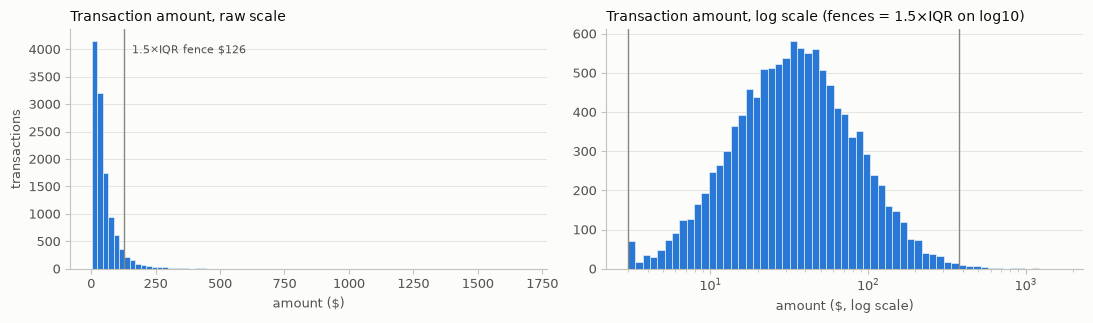

In [9]:
amount = transactions["amount"]
q1, q3 = amount.quantile([0.25, 0.75])
raw_fence = q3 + 1.5 * (q3 - q1)
log_amount = np.log10(amount)
lq1, lq3 = log_amount.quantile([0.25, 0.75])
log_lo, log_hi = lq1 - 1.5 * (lq3 - lq1), lq3 + 1.5 * (lq3 - lq1)

print(f"amount: mean ${amount.mean():.2f} vs median ${amount.median():.2f} | skew {stats.skew(amount):.2f} | "
      f"log10(amount) skew {stats.skew(log_amount):.2f}")
print(f"amount: min ${amount.min():.2f} | p25 ${q1:.2f} | p75 ${q3:.2f} | p99 ${amount.quantile(0.99):.2f} | max ${amount.max():.2f}")
print(f"1.5xIQR, raw scale : upper fence ${raw_fence:.2f} -> {int((amount > raw_fence).sum())} high outliers "
      f"({(amount > raw_fence).mean():.1%} of transactions); 3xIQR flags {int((amount > q3 + 3 * (q3 - q1)).sum())}")
print(f"1.5xIQR, log scale : fences ${10 ** log_lo:.4f} / ${10 ** log_hi:.2f} -> "
      f"{int(((log_amount < log_lo) | (log_amount > log_hi)).sum())} outliers "
      f"({int((log_amount < log_lo).sum())} low, {int((log_amount > log_hi).sum())} high)")
at_min = amount == amount.min()
next_band = (amount > amount.min()) & (amount <= amount.min() + 0.5)
print(f"transactions at exactly the minimum ${amount.min():.2f}: {int(at_min.sum())} ({at_min.mean():.2%}) vs "
      f"{int(next_band.sum())} in the next 50 cents (${amount.min():.2f}, ${amount.min() + 0.5:.2f}]")
print("the log-scale low outliers are exactly the minimum-value rows:",
      bool(((log_amount < log_lo) == at_min).all()))
print("\nten largest transactions:")
display(transactions.nlargest(10, "amount")[["customer_id", "txn_timestamp", "category", "channel", "amount", "is_returned"]])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.3))
ax1.hist(amount, bins=80, color=BLUE, edgecolor=SURFACE, linewidth=0.4)
ax1.axvline(raw_fence, color=MUTED, linewidth=1)
ax1.annotate(f"1.5×IQR fence ${raw_fence:.0f}", xy=(raw_fence, ax1.get_ylim()[1] * 0.9), xytext=(6, 0),
             textcoords="offset points", color=INK_2, fontsize=8)
ax1.set(title="Transaction amount, raw scale", xlabel="amount ($)", ylabel="transactions")
bins = np.logspace(np.log10(amount.min()), np.log10(amount.max()), 60)
ax2.hist(amount, bins=bins, color=BLUE, edgecolor=SURFACE, linewidth=0.4)
ax2.set_xscale("log")
for fence in (10 ** log_lo, 10 ** log_hi):
    ax2.axvline(fence, color=MUTED, linewidth=1)
ax2.set(title="Transaction amount, log scale (fences = 1.5×IQR on log10)", xlabel="amount ($, log scale)")
for ax in (ax1, ax2):
    ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

**Read.** **[computed]** `amount` is strongly right-skewed: the mean is \$49.72 against a median of \$33.82, the skew is 6.11, and the maximum is \$1,684.21. On a log scale it is close to symmetric (log10 skew −0.01). **[eyeballed]** Together with the histogram, that suggests a roughly log-normal shape, but I have not run a formal fit.

**[computed]** The outlier count depends heavily on the rule. 1.5×IQR on the raw scale flags **783 transactions (6.7%)** above \$125.93. That mostly looks like the natural long tail, not errors. The same rule on the log scale flags **86**: 34 high and 52 low. **Low confidence:** I have not decided which rule is right, and I have not checked whether the largest amounts are genuine.

**[computed; the cause is a guess]** There is a **pile-up at the minimum**. 52 transactions (0.44%) sit at exactly \$3.00, against only 25 in the next 50 cents. Those 52 are precisely the log-scale "low outliers". This looks like a floor or clip on `amount` at \$3.00, not real small purchases, but nothing documents it.

**[computed]** The parquet columns are also right-skewed. `txn_count` runs 1–6 (median 1), `total_amount` runs \$3.00–\$1,753.23, and `return_count` runs 0–3 (mostly 0). Returns are 591 of 11,742 transactions (5.03%).

,n,mean,median,skew,shape,min,q1,q3,max,lower_fence,upper_fence,n_outliers_1.5iqr
tenure_days,1500,467.610,468.000,-0.030,roughly symmetric,30.000,253.750,690.250,898.000,-401.000,1345.000,0
n_txn,1419,8.275,7.000,0.713,right-skewed,1.000,4.000,12.000,32.000,-8.000,24.000,4
total_spend,1419,411.427,354.860,1.029,right-skewed,4.290,191.355,570.500,1883.860,-377.362,1139.218,30
avg_order_value,1419,50.481,45.781,2.870,right-skewed,4.290,35.967,58.741,286.360,1.807,92.901,69
return_rate,1419,0.053,0.000,4.077,right-skewed,0.000,0.000,0.083,1.000,-0.125,0.208,93
n_returns,1419,0.416,0.000,1.949,right-skewed,0.000,0.000,1.000,5.000,-1.500,2.500,24
n_categories,1419,4.123,4.000,-0.506,left-skewed,1.000,3.000,5.000,6.000,0.000,8.000,0
days_since_last_txn,1419,37.427,26.000,2.427,right-skewed,0.000,10.000,52.500,365.000,-53.750,116.250,57
txn_last_90d,1419,2.420,2.000,1.319,right-skewed,0.000,1.000,3.000,12.000,-2.000,6.000,33
spend_last_90d,1419,122.771,88.940,1.958,right-skewed,0.000,35.600,174.045,1004.220,-172.068,381.713,49


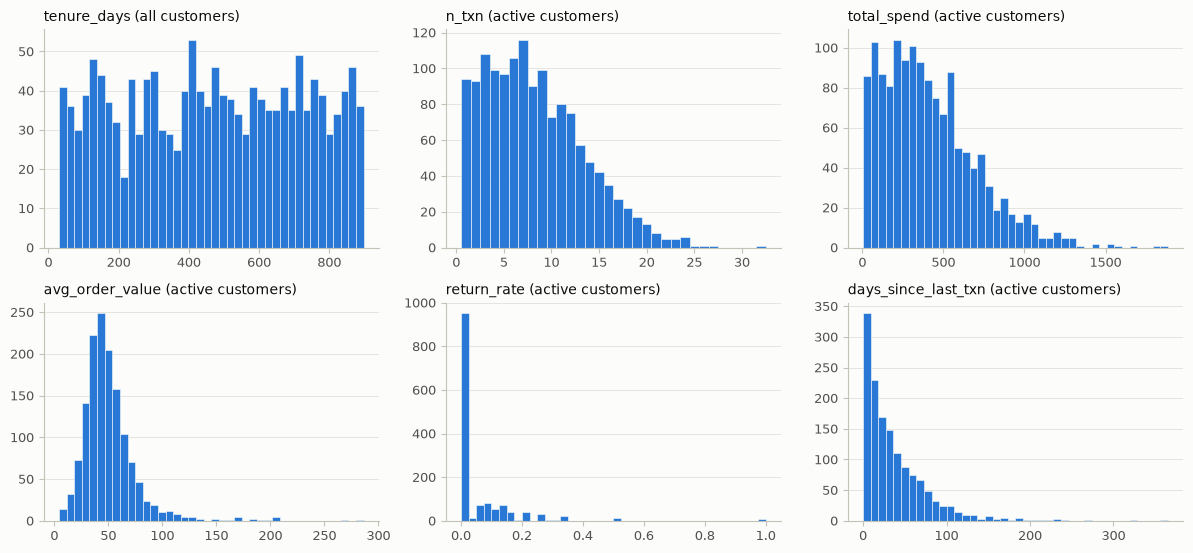

In [10]:
feature_cols = ["tenure_days", "n_txn", "total_spend", "avg_order_value", "return_rate", "n_returns",
                "n_categories", "days_since_last_txn", "txn_last_90d", "spend_last_90d", "txn_per_30d_tenure",
                "share_mobile_app", "share_store", "share_web"]
# tenure exists for every customer; transaction-derived features are profiled over active customers only.
dist = pd.DataFrame.from_dict(
    {c: shape_summary(cust[c] if c == "tenure_days" else active[c]) for c in feature_cols}, orient="index"
)
display(dist.round(3))

fig, axes = plt.subplots(2, 3, figsize=(12, 5.6))
for ax, col in zip(axes.flat, ["tenure_days", "n_txn", "total_spend", "avg_order_value", "return_rate",
                               "days_since_last_txn"]):
    data = (cust[col] if col == "tenure_days" else active[col]).dropna()
    bins = np.arange(0.5, data.max() + 1.5, 1) if col == "n_txn" else 40  # unit bins for a count
    ax.hist(data, bins=bins, color=BLUE, edgecolor=SURFACE, linewidth=0.4)
    who = "all customers" if col == "tenure_days" else "active customers"
    ax.set(title=f"{col} ({who})")
    ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

**Read [computed].** Most spend and frequency features are right-skewed: `total_spend` skew 1.03, `avg_order_value` 2.87, `n_txn` 0.71. `return_rate` is zero-inflated (median 0, skew 4.08), and most customers never return anything. `tenure_days` is roughly symmetric (skew −0.03). `n_categories` leans slightly left (skew −0.51), meaning most customers buy across 4–6 categories. Whatever downstream summary is used for the monetary features, it should be median/IQR rather than mean/std.

## 7. Category / channel / region breakdowns

In [11]:
def txn_breakdown(col: str) -> pd.DataFrame:
    out = transactions.groupby(col).agg(n_txn=("amount", "size"), median_amount=("amount", "median"),
                                        mean_amount=("amount", "mean"), return_rate=("is_returned", "mean"))
    out.insert(1, "share", out["n_txn"] / len(transactions))
    return out.sort_values("n_txn", ascending=False)


def customer_breakdown(col: str) -> pd.DataFrame:
    out = customers.groupby(col).agg(n_customers=("customer_id", "size"), zero_activity_share=("zero_activity", "mean"))
    out.insert(1, "share", out["n_customers"] / len(customers))
    return out.sort_values("n_customers", ascending=False)


print("transactions by category"); display(txn_breakdown("category").round(4))
print("transactions by channel"); display(txn_breakdown("channel").round(4))
print("channel mix within each category (row %)")
display((100 * pd.crosstab(transactions["category"], transactions["channel"], normalize="index")).round(1))
print("customers by region"); display(customer_breakdown("region").round(4))
print("customers by acquisition_channel"); display(customer_breakdown("acquisition_channel").round(4))
print("region x acquisition_channel (customers)")
display(pd.crosstab(customers["region"], customers["acquisition_channel"], margins=True))

transactions by category


,n_txn,share,median_amount,mean_amount,return_rate
category,,,,,
home,2008,0.1710,33.850,48.3824,0.0513
grocery,1979,0.1685,34.160,47.9492,0.0566
sports,1969,0.1677,34.730,49.0366,0.0528
beauty,1958,0.1668,32.955,49.2221,0.0506
apparel,1917,0.1633,33.930,50.7579,0.0449
electronics,1911,0.1627,33.410,53.1338,0.0455


transactions by channel


,n_txn,share,median_amount,mean_amount,return_rate
channel,,,,,
web,5278,0.4495,33.555,48.8074,0.0512
mobile_app,4146,0.3531,34.080,50.7544,0.0511
store,2318,0.1974,33.830,49.9489,0.0470


channel mix within each category (row %)


channel,mobile_app,store,web
category,,,
apparel,35.9,20.2,43.8
beauty,35.1,19.4,45.6
electronics,35.4,18.1,46.5
grocery,36.6,20.4,43.0
home,33.6,21.1,45.3
sports,35.2,19.2,45.6


... (2 outputs left out)

customers by acquisition_channel


,n_customers,share,zero_activity_share
acquisition_channel,,,
organic,609,0.4060,0.0575
paid_search,431,0.2873,0.0441
referral,295,0.1967,0.0678
social,165,0.1100,0.0424


region x acquisition_channel (customers)


acquisition_channel,organic,paid_search,referral,social,All
region,,,,,
east,169,105,73,38,385
north,152,103,81,45,381
south,130,112,76,36,354
west,158,111,65,46,380
All,609,431,295,165,1500


**Read [computed].** Transactions are spread almost evenly across the six categories (1,911–2,008 each, about 16–17%). By channel, web carries 45.0%, mobile_app 35.3% and store 19.7%. The median amount barely moves by category (\$32.96–\$34.73) or by channel. **The return rate is about 5% everywhere:** 4.70–5.12% by channel and 4.49–5.66% by category. The channel mix is nearly identical within every category. On the customer side, regions are close to balanced (354–385 customers each). By acquisition channel the split is organic 40.6%, paid_search 28.7%, referral 19.7% and social 11.0%. The zero-activity share sits between about 4% and 7% in every channel and region.

## 8. Churn rate: overall and by candidate categorical drivers

Every split is shown both for **all customers** and for **active customers only**. All 81 zero-activity customers are churned, so they can move a group's churn rate on their own.

**No significance tests are run in this pass.** These are descriptive rates only.

In [12]:
n_churn = int(cust["churned"].sum())
print(f"overall churn rate      : {n_churn} of {len(cust):,} = {n_churn / len(cust):.2%}")
print(f"active customers only   : {int(active['churned'].sum())} of {len(active):,} = {active['churned'].mean():.2%}")
print(f"zero-activity customers : {int(cust.loc[cust['zero_activity'], 'churned'].sum())} of "
      f"{int(cust['zero_activity'].sum())} = {cust.loc[cust['zero_activity'], 'churned'].mean():.0%}")
print(f"always predicting 'not churned' scores {1 - n_churn / len(cust):.2%} accuracy "
      f"({1 - active['churned'].mean():.2%} on active customers)")

overall churn rate      : 202 of 1,500 = 13.47%
active customers only   : 121 of 1,419 = 8.53%
zero-activity customers : 81 of 81 = 100%
always predicting 'not churned' scores 86.53% accuracy (91.47% on active customers)


In [13]:
def churn_by(df: pd.DataFrame, col: str) -> pd.DataFrame:
    out = df.groupby(col, observed=True)["churned"].agg(n="size", churned="sum", churn_rate="mean")
    out["churn_rate"] = (100 * out["churn_rate"]).round(1)
    return out


for col in ["acquisition_channel", "region", "signup_quarter", "tenure_bucket"]:
    print(f"\nchurn rate (%) by {col}")
    display(pd.concat({"all customers": churn_by(cust, col), "active only": churn_by(active, col)}, axis=1))
for col in ["dominant_category", "dominant_channel"]:
    print(f"\nchurn rate (%) by {col}  (active customers only - undefined for zero-activity customers)")
    display(churn_by(active, col))


churn rate (%) by acquisition_channel


all customers                    active only                   
                                n churned churn_rate           n churned churn_rate
acquisition_channel                                                                
organic                       609      93       15.3         574      58       10.1
paid_search                   431      44       10.2         412      25        6.1
referral                      295      41       13.9         275      21        7.6
social                        165      24       14.5         158      17       10.8


churn rate (%) by region


all customers                    active only                   
                   n churned churn_rate           n churned churn_rate
region                                                                
east             385      63       16.4         363      41       11.3
north            381      47       12.3         362      28        7.7
south            354      45       12.7         334      25        7.5
west             380      47       12.4         360      27        7.5


churn rate (%) by signup_quarter


all customers                    active only                   
                           n churned churn_rate           n churned churn_rate
signup_quarter                                                                
2024Q1                    90       7        7.8          90       7        7.8
2024Q2                   148      12        8.1         148      12        8.1
2024Q3                   175      17        9.7         175      17        9.7
2024Q4                   157      16       10.2         157      16       10.2
2025Q1                   144      13        9.0         144      13        9.0
2025Q2                   180      22       12.2         179      21       11.7
2025Q3                   138      16       11.6         138      16       11.6
2025Q4                   151      11        7.3         151      11        7.3
2026Q1                   159      28       17.6         139       8        5.8
2026Q2                   155      58       37.4          97       0        0.0
2026Q3                     3       2       66.7           1       0        0.0

... (2 outputs left out)


churn rate (%) by dominant_category  (active customers only - undefined for zero-activity customers)


,n,churned,churn_rate
dominant_category,,,
apparel,361,29,8.0
beauty,302,28,9.3
electronics,237,30,12.7
grocery,212,7,3.3
home,167,16,9.6
sports,140,11,7.9



churn rate (%) by dominant_channel  (active customers only - undefined for zero-activity customers)


,n,churned,churn_rate
dominant_channel,,,
mobile_app,589,49,8.3
store,144,16,11.1
web,686,56,8.2


In [14]:
# Sensitivity check: the dominant_* features above break ties alphabetically-first. Re-run with alphabetically-last.
alt_rule = pd.DataFrame({
    "dominant_category": category_counts[category_counts.columns[::-1]].idxmax(axis=1),
    "dominant_channel": channel_counts[channel_counts.columns[::-1]].idxmax(axis=1),
})
active_alt = active.drop(columns=["dominant_category", "dominant_channel"]).join(alt_rule, on="customer_id")
for col in ["dominant_category", "dominant_channel"]:
    print(f"\n{col}: churn rate (%) under two tie-break rules (active customers)")
    display(pd.concat({"ties -> alphabetically first (used above)": churn_by(active, col),
                       "ties -> alphabetically last": churn_by(active_alt, col)}, axis=1))


dominant_category: churn rate (%) under two tie-break rules (active customers)


ties -> alphabetically first (used above)                    ties -> alphabetically last                   
                                                          n churned churn_rate                           n churned churn_rate
dominant_category                                                                                                            
apparel                                                 361      29        8.0                         154      17       11.0
beauty                                                  302      28        9.3                         189      16        8.5
electronics                                             237      30       12.7                         194      24       12.4
grocery                                                 212       7        3.3                         228       7        3.1
home                                                    167      16        9.6                         300      25        8.3
sports                                                  140      11        7.9                         354      32        9.0


dominant_channel: churn rate (%) under two tie-break rules (active customers)


ties -> alphabetically first (used above)                    ties -> alphabetically last                   
                                                         n churned churn_rate                           n churned churn_rate
dominant_channel                                                                                                            
mobile_app                                             589      49        8.3                         382      35        9.2
store                                                  144      16       11.1                         127      12        9.4
web                                                    686      56        8.2                         910      74        8.1

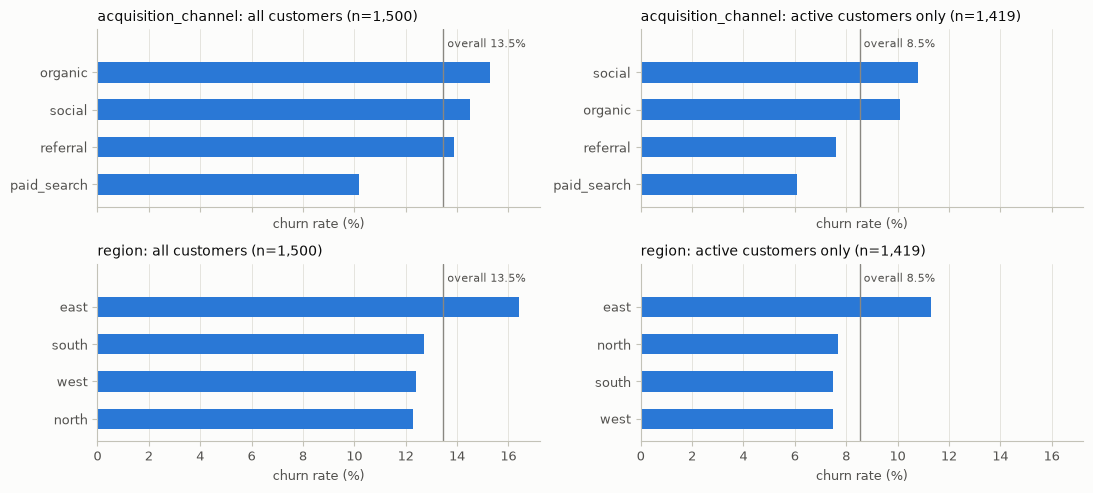

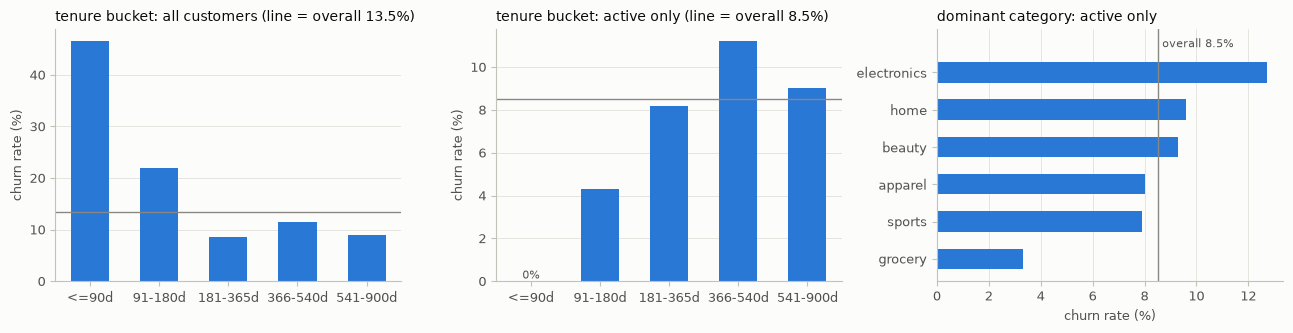

In [15]:
def churn_bars(ax, table: pd.DataFrame, overall: float, title: str, horizontal: bool = True) -> None:
    t = table.sort_values("churn_rate") if horizontal else table
    labels = t.index.astype(str)
    if horizontal:
        ax.barh(labels, t["churn_rate"], height=0.55, color=BLUE)
        ax.axvline(100 * overall, color=MUTED, linewidth=1)
        ax.set_ylim(-0.6, len(t) + 0.15)  # headroom so the reference label sits inside the plot
        ax.text(100 * overall, len(t) - 0.4, f" overall {100 * overall:.1f}%", color=INK_2, fontsize=8,
                va="bottom")
        ax.set_xlabel("churn rate (%)")
        ax.grid(axis="y", visible=False)
        ax.set_title(title)
    else:
        ax.bar(labels, t["churn_rate"], width=0.55, color=BLUE)
        ax.axhline(100 * overall, color=MUTED, linewidth=1)
        for i, v in enumerate(t["churn_rate"]):
            if v == 0:  # a zero-height bar is invisible - say so rather than let it read as missing
                ax.text(i, 0, "0%", ha="center", va="bottom", color=INK_2, fontsize=8)
        ax.set_ylabel("churn rate (%)")
        ax.grid(axis="x", visible=False)
        ax.set_title(f"{title} (line = overall {100 * overall:.1f}%)")


fig, axes = plt.subplots(2, 2, figsize=(11, 5), sharex=True)
for row, col in enumerate(["acquisition_channel", "region"]):
    churn_bars(axes[row, 0], churn_by(cust, col), cust["churned"].mean(), f"{col}: all customers (n={len(cust):,})")
    churn_bars(axes[row, 1], churn_by(active, col), active["churned"].mean(),
               f"{col}: active customers only (n={len(active):,})")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
churn_bars(axes[0], churn_by(cust, "tenure_bucket"), cust["churned"].mean(), "tenure bucket: all customers",
           horizontal=False)
churn_bars(axes[1], churn_by(active, "tenure_bucket"), active["churned"].mean(), "tenure bucket: active only",
           horizontal=False)
churn_bars(axes[2], churn_by(active, "dominant_category"), active["churned"].mean(),
           "dominant category: active only")
plt.tight_layout()
plt.show()

**Read.** **[computed]** The overall churn rate is **13.47% (202 of 1,500)**. Among active customers it is 8.53% (121 of 1,419), and among zero-activity customers it is 100%. A model that always predicts "not churned" scores 86.53% accuracy.

Candidate categorical drivers. **[eyeballed: descriptive rates only, no test run]**
- **acquisition_channel:** paid_search is lowest (10.2% all / 6.1% active). organic (15.3% / 10.1%) and social (14.5% / 10.8%) are highest.
- **region:** east is highest (16.4% / 11.3%). The other three regions sit at 12.3–12.7% for all customers and 7.5–7.7% for active ones.
- **dominant_category (active only):** customers who mostly buy grocery churn at **3.3% (7 of 212)**, against 7.9–12.7% for every other category (electronics is highest at 12.7%). This is the biggest categorical gap I saw, but it rests on only 7 churners.
- **dominant_channel (active only):** store-dominant customers churn at 11.1% (16 of 144), against 8.2–8.3% for mobile_app and web. The group is small.
- **Caveat on both `dominant_*` features (low confidence):** the top value is *tied* for 36.1% of active customers on category and 18.5% on channel. The main tables give ties to the alphabetically first value, and the sensitivity table re-runs them giving ties to the alphabetically last.
  - **Grocery stays lowest under both rules** (3.3% / 3.1%) and **electronics stays highest** (12.7% / 12.4%).
  - Group sizes swing a lot, for example apparel goes from 361 to 154 customers.
  - **The store-channel gap does not survive the change:** 11.1% falls to 9.4%, against 8.1–9.2% for the other channels. Treat it as noise until tested.

Gaps of a few percentage points between groups of a few hundred customers can easily be noise. Each of these needs a real test before it is called a driver.

**Tenure and signup cohort: the direction flips depending on population.** **[computed]** For the numbers. **Interpretation: low confidence.**
- Recent cohorts look very high-churn overall (2026Q2: 37.4%). Among active customers the same cohort churns at **0.0%**, so the overall figure comes from the zero-activity customers, who are concentrated in recent signups.
- By tenure bucket, all customers with ≤90 days of tenure churn at 46.5%, while active customers in that bucket churn at 0.0%. Among active customers, churn *rises* with tenure: 0.0% (≤90d), 4.3% (91–180d), 8.2% (181–365d), 11.2% (366–540d), then 9.0% (541–900d).
- I have not worked out why the direction flips. Until that is looked at properly, treat tenure as confounded with the zero-activity group.

## 9. Numeric features vs. churn: first-pass separation (no tests)

The separation measure is the **single-feature ROC-AUC**, computed from ranks: the probability that a random churner has a higher value than a random retained customer, with ties counted half. 0.5 means no separation. 1.0 or 0.0 means perfect separation, in opposite directions. `separation` = max(AUC, 1 − AUC). This is a **descriptive** measure, not a hypothesis test, and no p-values are computed in this pass. The population is **active customers**, because transaction features are undefined for zero-activity customers.

In [16]:
def rank_auc(values: pd.Series, label: pd.Series) -> float:
    # P(value for a random churner > value for a random retained customer); ties count half.
    ranks = stats.rankdata(values)
    pos = label.to_numpy() == 1
    n1, n0 = int(pos.sum()), int((~pos).sum())
    return float((ranks[pos].sum() - n1 * (n1 + 1) / 2) / (n1 * n0))


numeric_candidates = ["days_since_last_txn", "txn_last_90d", "spend_last_90d", "txn_per_30d_tenure",
                      "tenure_days", "n_txn", "total_spend", "n_categories", "share_store", "share_web",
                      "avg_order_value", "n_returns", "return_rate", "share_mobile_app"]
rows = []
for feat in numeric_candidates:
    d = active[[feat, "churned"]].dropna()
    auc = rank_auc(d[feat], d["churned"])
    rows.append({"feature": feat,
                 "median_churned": d.loc[d["churned"] == 1, feat].median(),
                 "median_retained": d.loc[d["churned"] == 0, feat].median(),
                 "auc": auc, "separation": max(auc, 1 - auc),
                 "churners_have": "higher" if auc > 0.5 else "lower" if auc < 0.5 else "same"})
separation = pd.DataFrame(rows).set_index("feature").sort_values("separation", ascending=False)
display(separation.round(3))

auc_tenure_all = rank_auc(cust["tenure_days"], cust["churned"])
print(f"tenure_days on ALL {len(cust):,} customers: AUC {auc_tenure_all:.3f} "
      f"(churners have {'higher' if auc_tenure_all > 0.5 else 'lower'} tenure) - "
      f"vs {separation.loc['tenure_days', 'auc']:.3f} on active customers only")

,median_churned,median_retained,auc,separation,churners_have
feature,,,,,
days_since_last_txn,113.000,23.000,1.000,1.000,higher
txn_last_90d,0.000,2.000,0.000,1.000,lower
spend_last_90d,0.000,103.295,0.000,1.000,lower
txn_per_30d_tenure,0.335,0.513,0.265,0.735,lower
total_spend,282.390,364.380,0.392,0.608,lower
n_txn,6.000,8.000,0.396,0.604,lower
n_categories,4.000,4.000,0.408,0.592,lower
share_store,0.111,0.175,0.445,0.555,lower
tenure_days,507.000,486.500,0.547,0.547,higher


tenure_days on ALL 1,500 customers: AUC 0.346 (churners have lower tenure) - vs 0.547 on active customers only


,count,min,median,max
churned,,,,
0,1298,0.0,23.0,90.0
1,121,91.0,113.0,365.0


churners: min 91 days since last transaction | retained: max 90 days
a 90-day recency cut-off reproduces the churned label for 100.00% of the 1,419 active customers
txn_last_90d among active churners: {0.0: 121} | spend_last_90d max among active churners: 0.0
median spend_last_90d among retained customers: $103.29


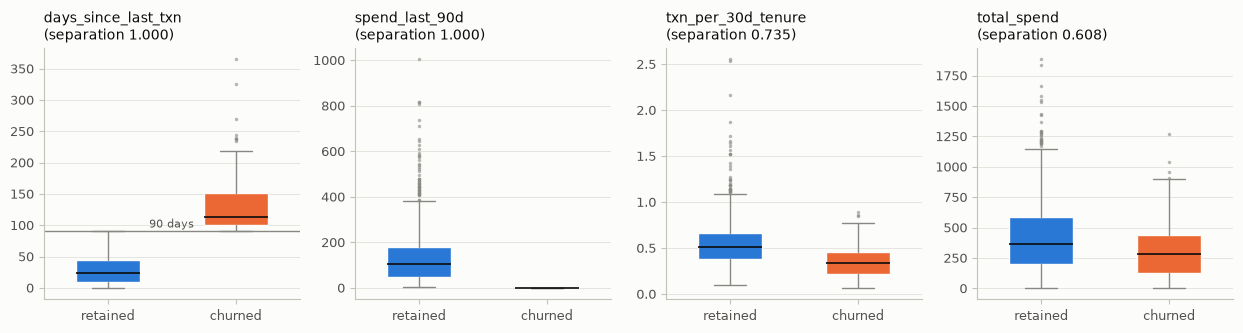

In [17]:
recency = active.groupby("churned")["days_since_last_txn"].agg(["count", "min", "median", "max"])
display(recency)
cut = (active["days_since_last_txn"] > 90).astype(int)
print(f"churners: min {recency.loc[1, 'min']:.0f} days since last transaction | "
      f"retained: max {recency.loc[0, 'max']:.0f} days")
print(f"a 90-day recency cut-off reproduces the churned label for {(cut == active['churned']).mean():.2%} "
      f"of the {len(active):,} active customers")
print("txn_last_90d among active churners:", active.loc[active["churned"] == 1, "txn_last_90d"].value_counts().to_dict(),
      "| spend_last_90d max among active churners:", active.loc[active["churned"] == 1, "spend_last_90d"].max())
print(f"median spend_last_90d among retained customers: ${active.loc[active['churned'] == 0, 'spend_last_90d'].median():.2f}")

fig, axes = plt.subplots(1, 4, figsize=(12.5, 3.4))
for ax, feat in zip(axes, ["days_since_last_txn", "spend_last_90d", "txn_per_30d_tenure", "total_spend"]):
    groups = [active.loc[active["churned"] == 0, feat], active.loc[active["churned"] == 1, feat]]
    bp = ax.boxplot(groups, patch_artist=True, widths=0.5, tick_labels=["retained", "churned"],
                    medianprops=dict(color=INK, linewidth=1.2), whiskerprops=dict(color=MUTED),
                    capprops=dict(color=MUTED),
                    flierprops=dict(marker="o", markersize=2.5, markerfacecolor=MUTED, markeredgecolor="none",
                                    alpha=0.6))
    for patch, colour in zip(bp["boxes"], [BLUE, ORANGE]):
        patch.set_facecolor(colour)
        patch.set_edgecolor(SURFACE)
    ax.set_title(f"{feat}\n(separation {separation.loc[feat, 'separation']:.3f})")
    ax.grid(axis="x", visible=False)
axes[0].axhline(90.5, color=MUTED, linewidth=1)
axes[0].text(1.5, 92, "90 days", color=INK_2, fontsize=8, ha="center", va="bottom")
plt.tight_layout()
plt.show()

**Read.** **[computed] The strongest signal by far is recency.** Among active customers, `days_since_last_txn` separates churners from retained customers **perfectly** in this snapshot, with a single-feature AUC of **1.000**. Every churner is at 91 days or more and every retained customer is at 90 or fewer, so a 90-day cut-off classifies all 1,419 active customers correctly. The trailing-90-day activity features are just as clean: every churner has `txn_last_90d = 0` and `spend_last_90d = 0`, while retained customers have a median of \$103.29 in that window. Taken at face value, this is the headline predictor of the first pass.

**[computed]** The next tier is much weaker:
- **Purchase rate.** `txn_per_30d_tenure` has a separation of 0.735, and churners buy less often (median 0.335 vs. 0.513 transactions per 30 days).
- **Lifetime volume.** `n_txn` and `total_spend` sit around 0.60, with churners lower.
- **Basket.** `n_categories` and `share_store` show small separation.
- **No separation.** `avg_order_value`, `return_rate` and the mobile/web shares are close to 0.5.

**[computed numbers; interpretation low confidence]** `tenure_days` separates in *opposite* directions depending on population. Across all customers, churners have shorter tenure (AUC 0.346). Among active customers, churners have *longer* tenure (AUC 0.547; median 507 vs. 486.5 days). This is the same flip as in section 8 and has not been resolved.

## 10. Monthly transaction-volume trend

This uses the row-level table (`transactions.db`), because it is the complete source (see section 11). The trend is characterised with numbers rather than asserted: the rank correlation with time, the month-over-month declines, and per-customer intensity.

In [18]:
trend = transactions.groupby("txn_month").agg(
    txn_count=("amount", "size"), total_amount=("amount", "sum"),
    active_customers=("customer_id", "nunique"), returns=("is_returned", "sum"),
)
trend["txn_per_active_customer"] = trend["txn_count"] / trend["active_customers"]
trend["avg_ticket"] = trend["total_amount"] / trend["txn_count"]
trend["return_rate"] = trend["returns"] / trend["txn_count"]
signups = customers.groupby(customers["signup_date"].dt.to_period("M").dt.to_timestamp()).size()
trend["new_signups"] = signups.reindex(trend.index, fill_value=0)
trend["mom_change"] = trend["txn_count"].diff()
display(trend.round(3))

declines = trend.index[trend["mom_change"] < 0]
rho = stats.spearmanr(np.arange(len(trend)), trend["txn_count"]).statistic
last12 = trend.iloc[-12:]
middle = trend["new_signups"].iloc[1:-1]  # first and last months are partial
print(f"{len(trend)} months, {trend.index.min():%Y-%m} -> {trend.index.max():%Y-%m}")
print(f"txn_count: {trend['txn_count'].iloc[0]} in {trend.index[0]:%Y-%m} -> {trend['txn_count'].iloc[-1]:,} in {trend.index[-1]:%Y-%m}")
print(f"Spearman rank correlation of monthly txn_count with time: {rho:.3f}")
print(f"month-over-month declines in txn_count: {len(declines)} -> {[f'{m:%Y-%m}' for m in declines]}")
yoy_from, yoy_to = trend.loc["2025-07-01", "txn_count"], trend.loc["2026-07-01", "txn_count"]
print(f"2025-07 -> 2026-07: {yoy_from} -> {yoy_to:,} transactions ({yoy_to / yoy_from - 1:+.0%})")
print(f"last 12 months: txn per active customer {last12['txn_per_active_customer'].min():.2f}-"
      f"{last12['txn_per_active_customer'].max():.2f} | avg ticket ${last12['avg_ticket'].min():.2f}-"
      f"${last12['avg_ticket'].max():.2f} | return rate {last12['return_rate'].min():.1%}-{last12['return_rate'].max():.1%}")
print(f"new signups per full month: {middle.min()}-{middle.max()} (median {middle.median():.0f})")

,txn_count,total_amount,active_customers,returns,txn_per_active_customer,avg_ticket,return_rate,new_signups,mom_change
txn_month,,,,,,,,,
2024-02-01,1,25.03,1,0,1.000,25.030,0.000,27,NaN
2024-03-01,3,78.11,3,0,1.000,26.037,0.000,63,2.0
2024-04-01,5,239.77,5,0,1.000,47.954,0.000,50,2.0
2024-05-01,17,576.31,13,1,1.308,33.901,0.059,43,12.0
2024-06-01,19,772.03,16,0,1.188,40.633,0.000,55,2.0
2024-07-01,31,1510.70,24,4,1.292,48.732,0.129,49,12.0
2024-08-01,42,2128.91,33,2,1.273,50.688,0.048,74,11.0
2024-09-01,69,3858.07,53,4,1.302,55.914,0.058,52,27.0
2024-10-01,85,4105.74,58,5,1.466,48.303,0.059,49,16.0


30 months, 2024-02 -> 2026-07
txn_count: 1 in 2024-02 -> 1,231 in 2026-07
Spearman rank correlation of monthly txn_count with time: 0.998
month-over-month declines in txn_count: 3 -> ['2024-11', '2025-11', '2026-02']
2025-07 -> 2026-07: 367 -> 1,231 transactions (+235%)
last 12 months: txn per active customer 1.34-1.56 | avg ticket $46.64-$55.15 | return rate 3.2%-6.3%
new signups per full month: 40-74 (median 50)


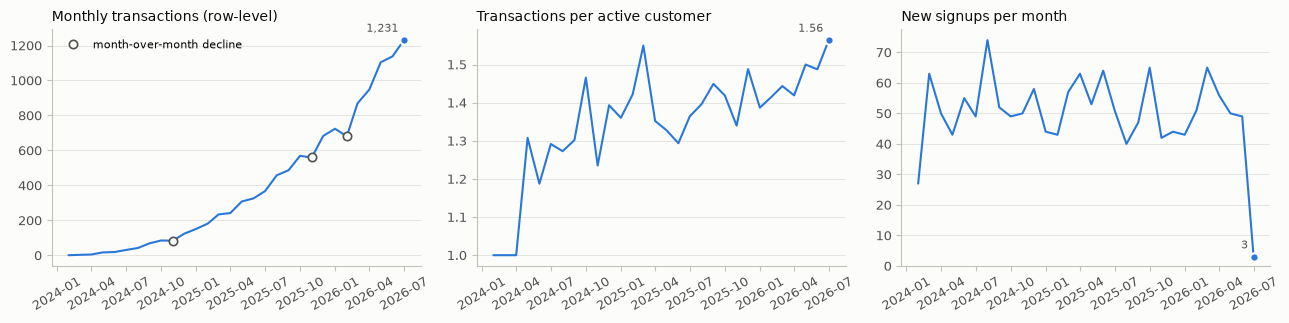

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.3))
panels = [("txn_count", "Monthly transactions (row-level)"),
          ("txn_per_active_customer", "Transactions per active customer"),
          ("new_signups", "New signups per month")]
for ax, (col, title) in zip(axes, panels):
    ax.plot(trend.index, trend[col], color=BLUE)
    ax.plot(trend.index[-1], trend[col].iloc[-1], "o", color=BLUE, markersize=6, markeredgecolor=SURFACE,
            markeredgewidth=1.5)
    ax.annotate(f"{trend[col].iloc[-1]:,.2f}".rstrip("0").rstrip("."), xy=(trend.index[-1], trend[col].iloc[-1]),
                xytext=(-4, 6), textcoords="offset points", ha="right", color=INK_2, fontsize=8)
    ax.set_title(title)
    ax.grid(axis="x", visible=False)
    ax.tick_params(axis="x", labelrotation=30)
axes[0].plot(declines, trend.loc[declines, "txn_count"], "o", markersize=6, markerfacecolor=SURFACE,
             markeredgecolor=INK_2, markeredgewidth=1.2, label="month-over-month decline")
axes[0].legend(frameon=False, fontsize=8, loc="upper left")
axes[2].set_ylim(bottom=0)
plt.tight_layout()
plt.show()

**Read.** **[computed]** Transaction volume has a strong upward trend: from 1 transaction in 2024-02 to 1,231 in 2026-07, with a Spearman ρ against time of **0.998**. **It is not strictly monotonic.** There are **3 month-over-month declines**, in 2024-11, 2025-11 and 2026-02. Year on year, 2025-07 → 2026-07 went from 367 to 1,231 transactions (+235%).

**[eyeballed; interpretation medium confidence]** Most of the growth looks like customer-base growth rather than customers buying more:
- New signups are roughly flat at 40–74 per full month (median 50), so the customer base keeps accumulating.
- Transactions per active customer only drift upward, staying within 1.34–1.56 over the last 12 months.
- Average ticket (\$46.64–\$55.15) and return rate (3.2%–6.3%) look flat.

I have not formally decomposed the trend. Either way, the data is clearly **not stationary in volume or in customer mix**. The last 12 months contain most of the transactions, and newer cohorts make up a growing share.

## 11. Quick check: parquet extract vs. row-level table

This was not on the Stage 0 list, but all three sources were already loaded, so it was worth a first look. First, month-level totals. Then a customer × month join. Then a probe for a date cutoff. The build stage should redo this properly rather than trust this pass.

In [20]:
row_level_month = transactions.groupby("txn_month").agg(
    txn_count=("amount", "size"), total_amount=("amount", "sum"), return_count=("is_returned", "sum"))
parquet_month = monthly.groupby("txn_month")[["txn_count", "total_amount", "return_count"]].sum()
src = row_level_month.merge(parquet_month, left_index=True, right_index=True, how="outer",
                            suffixes=("_rowlevel", "_parquet"))
for m in ["txn_count", "total_amount", "return_count"]:
    src[f"{m}_diff"] = src[f"{m}_rowlevel"] - src[f"{m}_parquet"]
src["total_amount_diff"] = src["total_amount_diff"].round(2)
month_mismatch = src[(src["txn_count_diff"] != 0) | (src["total_amount_diff"].abs() > 0.005)
                     | (src["return_count_diff"] != 0)]
print(f"months compared: {len(src)} | agree exactly: {len(src) - len(month_mismatch)} | disagree: {len(month_mismatch)}")
display(month_mismatch.round(2))
for _, r in month_mismatch.iterrows():
    print(f"{r.name:%Y-%m}: parquet is short by {r['txn_count_diff']:.0f} transactions "
          f"({r['txn_count_diff'] / r['txn_count_rowlevel']:.1%}), ${r['total_amount_diff']:,.2f} "
          f"({r['total_amount_diff'] / r['total_amount_rowlevel']:.1%} of the month's amount), "
          f"{r['return_count_diff']:.0f} returns")

months compared: 30 | agree exactly: 29 | disagree: 1


,txn_count_rowlevel,total_amount_rowlevel,return_count_rowlevel,txn_count_parquet,total_amount_parquet,return_count_parquet,txn_count_diff,total_amount_diff,return_count_diff
txn_month,,,,,,,,,
2026-07-01,1231,62084.62,67,994,50116.67,50,237,11967.95,17


2026-07: parquet is short by 237 transactions (19.3%), $11,967.95 (19.3% of the month's amount), 17 returns


In [21]:
row_level_cm = transactions.groupby(["customer_id", "txn_month"]).agg(
    txn_count=("amount", "size"), total_amount=("amount", "sum"), return_count=("is_returned", "sum")).reset_index()
cm = row_level_cm.merge(monthly, on=["customer_id", "txn_month"], how="outer",
                        suffixes=("_rowlevel", "_parquet"), indicator=True)
in_both = cm["_merge"] == "both"
values_differ = in_both & ((cm["txn_count_rowlevel"] != cm["txn_count_parquet"])
                           | ((cm["total_amount_rowlevel"] - cm["total_amount_parquet"]).abs() > 0.005)
                           | (cm["return_count_rowlevel"] != cm["return_count_parquet"]))
print(f"customer-month rows: row-level {len(row_level_cm):,} | parquet {len(monthly):,}")
print({"in both": int(in_both.sum()),
       "row-level only": int((cm["_merge"] == "left_only").sum()),
       "parquet only": int((cm["_merge"] == "right_only").sum())})
print(f"in both but values differ: {int(values_differ.sum())}")
print("months of every disagreeing customer-month:",
      sorted(cm.loc[values_differ | ~in_both, "txn_month"].dt.strftime("%Y-%m").unique()))

customer-month rows: row-level 8,188 | parquet 8,086
{'in both': 8086, 'row-level only': 102, 'parquet only': 0}
in both but values differ: 110
months of every disagreeing customer-month: ['2026-07']


In [22]:
july = transactions[transactions["txn_month"] == "2026-07-01"]
parquet_july = monthly[monthly["txn_month"] == "2026-07-01"].set_index("customer_id")[["txn_count", "total_amount"]]
probe = []
for cutoff in pd.date_range("2026-07-22", "2026-08-01", freq="D"):
    kept = july[july["txn_timestamp"] < cutoff]
    agg = kept.groupby("customer_id").agg(txn_count=("amount", "size"), total_amount=("amount", "sum"))
    j = agg.merge(parquet_july, left_index=True, right_index=True, how="outer", suffixes=("_rl", "_pq")).fillna(0)
    exact = ((j["txn_count_rl"] == j["txn_count_pq"]) & ((j["total_amount_rl"] - j["total_amount_pq"]).abs() < 0.005))
    probe.append({"keep row-level July rows with timestamp before": cutoff.date(), "rows_kept": len(kept),
                  "share_of_customers_matching_parquet_exactly": round(float(exact.mean()), 4)})
display(pd.DataFrame(probe))

missing_from_parquet = sorted(set(transactions["customer_id"]) - set(monthly["customer_id"]))
m = cust[cust["customer_id"].isin(missing_from_parquet)]
print(f"customers with transactions but no parquet rows: {len(missing_from_parquet)} | first transaction "
      f"{m['first_txn_date'].min().date()} -> {m['first_txn_date'].max().date()} | churned labels "
      f"{m['churned'].value_counts().to_dict()}")
print(f"zero-activity count if computed from the parquet instead: "
      f"{int((~customers['customer_id'].isin(monthly['customer_id'])).sum())} (vs {n_zero} from transactions.db)")
print(f"row-level transactions dated 2026-07-26 or later: {int((transactions['txn_timestamp'] >= '2026-07-26').sum())}")

,keep row-level July rows with timestamp before,rows_kept,share_of_customers_matching_parquet_exactly
0,2026-07-22,829,0.7796
1,2026-07-23,863,0.8234
2,2026-07-24,899,0.8715
3,2026-07-25,941,0.9255
4,2026-07-26,994,1.0000
5,2026-07-27,1032,0.9471
6,2026-07-28,1067,0.9036
7,2026-07-29,1104,0.8579
8,2026-07-30,1136,0.8224
9,2026-07-31,1193,0.7607


customers with transactions but no parquet rows: 10 | first transaction 2026-07-26 -> 2026-07-30 | churned labels {0: 10}
zero-activity count if computed from the parquet instead: 91 (vs 81 from transactions.db)
row-level transactions dated 2026-07-26 or later: 237


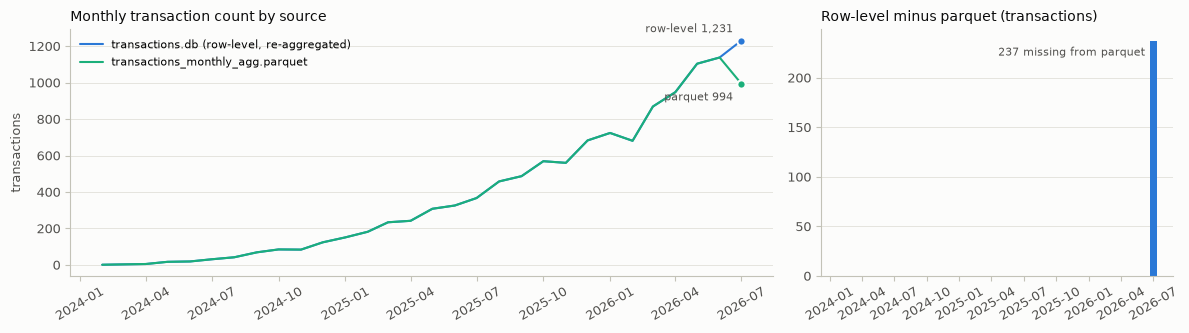

In [23]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.4), gridspec_kw={"width_ratios": [2, 1]})
ax1.plot(src.index, src["txn_count_rowlevel"], color=BLUE, label="transactions.db (row-level, re-aggregated)")
ax1.plot(src.index, src["txn_count_parquet"], color=AQUA, label="transactions_monthly_agg.parquet")
last = src.index[-1]
for col, colour, dy in [("txn_count_rowlevel", BLUE, 6), ("txn_count_parquet", AQUA, -12)]:
    ax1.plot(last, src.loc[last, col], "o", color=colour, markersize=6, markeredgecolor=SURFACE, markeredgewidth=1.5)
    ax1.annotate(f"{'row-level' if 'rowlevel' in col else 'parquet'} {src.loc[last, col]:,.0f}",
                 xy=(last, src.loc[last, col]), xytext=(-6, dy), textcoords="offset points", ha="right",
                 color=INK_2, fontsize=8)
ax1.set(title="Monthly transaction count by source", ylabel="transactions")
ax1.legend(frameon=False, fontsize=8, loc="upper left")
ax2.bar(src.index, src["txn_count_diff"], width=20, color=BLUE)
ax2.annotate(f"{src.loc[last, 'txn_count_diff']:.0f} missing from parquet", xy=(last, src.loc[last, "txn_count_diff"]),
             xytext=(-6, -4), textcoords="offset points", ha="right", va="top", color=INK_2, fontsize=8)
ax2.set(title="Row-level minus parquet (transactions)")
for ax in (ax1, ax2):
    ax.grid(axis="x", visible=False)
    ax.tick_params(axis="x", labelrotation=30)
plt.tight_layout()
plt.show()

**Read.** **[computed]** Month-level totals agree **exactly for 29 of 30 months**. **2026-07 disagrees.** The row-level table has 1,231 transactions and \$62,084.62, while the parquet has 994 and \$50,116.67. So **237 transactions (19.3%), \$11,967.95 (19.3% of the month's amount) and 17 returns are missing from the parquet**.

At customer × month grain, 102 row-level customer-months have no parquet row and 110 customer-months appear in both with different values. **All of them are in 2026-07.**

**[computed probe; the conclusion is an inference]** Cutting the row-level data at timestamps before **2026-07-26** reproduces the parquet's July rows exactly, for every customer. No other cutoff does. So the parquet looks like it was **extracted with data only through 2026-07-25**, which drops the last 6 days of July.

Consequences:
- 10 customers whose first-ever purchase was on or after 2026-07-26 are absent from the parquet entirely, and all of them are `churned = 0`.
- Counting zero-activity customers from the parquet would give **91 instead of 81**.
- Any recency or trailing-window feature built from the parquet would be wrong for those last 6 days.

## 12. Quick sanity checks (candidate leakage / integrity)

In [24]:
with_signup = transactions.merge(customers[["customer_id", "signup_date"]], on="customer_id", how="left")
checks = {
    "transactions dated before the customer's signup_date": int((with_signup["txn_date"] < with_signup["signup_date"]).sum()),
    "transactions whose customer_id is not in customers.csv": len(txn_ids - cust_ids),
    "exact duplicate transaction rows": int(transactions_raw.duplicated().sum()),
    "transactions after the assumed AS_OF (0 by construction)": int((transactions["txn_date"] > AS_OF).sum()),
    "parquet rows for months after the assumed AS_OF": int((monthly["txn_month"] > AS_OF).sum()),
    "customers with signup_date after the assumed AS_OF": int((customers["signup_date"] > AS_OF).sum()),
}
display(pd.Series(checks, name="count").to_frame())

,count
transactions dated before the customer's signup_date,0
transactions whose customer_id is not in customers.csv,0
exact duplicate transaction rows,0
transactions after the assumed AS_OF (0 by construction),0
parquet rows for months after the assumed AS_OF,0
customers with signup_date after the assumed AS_OF,0


**Read [computed].**
- No transaction precedes its customer's signup.
- There are no orphan transactions and no duplicate rows.
- There are no rows after `AS_OF`. **That last result is true by construction**, because `AS_OF` *is* the last date in the data, so it is not evidence of anything. If the real as-of date turns out to be earlier, this check has to be redone.

This is **not** a complete leakage audit. Only the checks above were run.

## 13. First-pass summary

| # | Observation | Tag |
|---|---|---|
| 1 | No nulls anywhere. **81 zero-activity customers (5.4%)**, all `churned = 1`, are **40.1% of churners**, and almost all are 2026 signups. | computed |
| 2 | Churn rate **13.47%** overall and **8.53%** among active customers. The accuracy of always predicting "not churned" is 86.53%. | computed |
| 3 | `amount` is strongly right-skewed (mean \$49.72 vs. median \$33.82, skew 6.11) and close to log-normal. Raw 1.5×IQR flags 783 rows (6.7%) and log-scale 1.5×IQR flags 86. The right rule is undecided. 52 rows pile up at exactly \$3.00, which looks like a floor. | computed / eyeballed |
| 4 | **Top predictor: recency.** `days_since_last_txn` separates churners perfectly among active customers (AUC 1.000, clean split at 90 days). Trailing-90-day transactions and spend are equally clean. | computed |
| 5 | Weaker numeric signal: purchase rate (separation 0.735), then lifetime `n_txn` / `total_spend` (about 0.60). `return_rate` and `avg_order_value` show essentially none. | computed |
| 6 | Categorical candidates: acquisition channel (paid_search lowest), region (east highest), dominant category (grocery 3.3%). `dominant_*` values are tie-sensitive. **No tests run.** | eyeballed |
| 7 | Tenure / cohort effect **flips direction** with or without the zero-activity customers. Not understood yet. | computed / low confidence |
| 8 | Monthly volume has a strong upward trend (ρ 0.998), mostly from customer-base growth. It is **not monotonic** (3 declines). | computed / eyeballed |
| 9 | The parquet is missing the last 6 days of July 2026 (237 transactions, \$11,967.95). Zero-activity from the parquet would be 91, not 81. | computed / inferred cutoff |
| 10 | `AS_OF` = 2026-07-31 is an **assumption** (the last transaction date). | assumption |

**Not done in this pass:**
- No hypothesis tests or p-values.
- No modelling.
- No check of the as-of date against any documentation.
- No complete leakage audit.
- No formal trend decomposition.
- No check of whether the largest amounts are genuine.

In [25]:
hashes_at_end = {p.name: sha256(p) for p in SOURCES}
assert hashes_at_end == HASHES_AT_START, "a data file changed while this notebook ran"
print("data files unchanged (SHA-256 identical at start and end):")
for name, digest in hashes_at_end.items():
    print(f"  {name:<36} {digest}")

data files unchanged (SHA-256 identical at start and end):
  customers.csv                        f5fcc5774eed070dbc70ebea24ded4493d839921e4a7f327e6726e3a993fbcd4
  transactions.db                      bd6d6683f676af933a24db910a3603bf3a26e773e23fe34334872c9d0b3abdfe
  transactions_monthly_agg.parquet     8861cd965172b5123f7928fb26cc26c6bd99c58053670802be608e09dddf665b
